In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from src.load import loadMatches, loadEvents, LEAKS

In [2]:
matches = loadMatches()
wc = matches[(matches["competition"] == "International - FIFA World Cup") & (matches["season"] == "2022")]
print(len(wc), "matches")

raw = []
for m in wc["match_id"]:
    ev = loadEvents(m)
    raw.append(ev[ev["type"] == "Shot"])
raw = pd.concat(raw, ignore_index=True)
print(raw.shape[0], "shots,", raw.shape[1], "columns")

64 matches
1494 shots, 114 columns


In [3]:
print("rows left after dropna():", len(raw.dropna()))

# flags only get written when they happened, so a blank means no, not missing
flags = ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal",
         "shot_aerial_won", "shot_follows_dribble", "shot_redirect", "shot_deflected"]
for f in flags:
    if f in raw.columns:
        print(f, "blank on", round(raw[f].isna().mean() * 100, 1), "% of shots")

print(raw["shot_type"].value_counts())
print(raw["period"].value_counts().sort_index())  # 5 is the shootout

rows left after dropna(): 0
under_pressure blank on 84.1 % of shots
shot_first_time blank on 68.7 % of shots
shot_one_on_one blank on 94.3 % of shots
shot_open_goal blank on 99.1 % of shots
shot_aerial_won blank on 91.4 % of shots
shot_follows_dribble blank on 99.8 % of shots
shot_redirect blank on 99.9 % of shots
shot_deflected blank on 98.5 % of shots
shot_type
Open Play    1382
Penalty        64
Free Kick      46
Corner          2
Name: count, dtype: int64
period
1    607
2    801
3     20
4     25
5     41
Name: count, dtype: int64


In [4]:
# the naive way: every column, text turned into dummies, blanks filled with 0, random split by shot
y = (raw["shot_outcome"] == "Goal").astype(int)

keep = []
for c in raw.columns:
    vals = raw[c].dropna()
    if len(vals) == 0:
        continue
    # lists and dicts (locations, freeze frames) can't go in as they are
    if isinstance(vals.iloc[0], (list, dict, np.ndarray)):
        continue
    # ids, timestamps and names have too many values to be dummies
    if not pd.api.types.is_numeric_dtype(raw[c]) and raw[c].nunique() > 50:
        continue
    keep.append(c)

X = pd.get_dummies(raw[keep]).fillna(0).astype(float)
print(X.shape[1], "columns after dummies")

Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, random_state=2026)
naive = XGBClassifier(n_estimators=200, max_depth=3).fit(Xa, ya)
print("naive AUC:", round(roc_auc_score(yb, naive.predict_proba(Xb)[:, 1]), 3))

141 columns after dummies
naive AUC: 1.0


In [5]:
imp = pd.Series(naive.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(8).round(3)

shot_outcome_Goal     0.997
shot_statsbomb_xg     0.003
index                 0.000
minute                0.000
match_id              0.000
period                0.000
player_id             0.000
possession_team_id    0.000
dtype: float32

In [6]:
# drop every column that comes from a leak
leakCols = []
for c in X.columns:
    for leak in LEAKS:
        if c == leak or c.startswith(leak + "_"):
            leakCols.append(c)
print("leak columns:", leakCols)

X2 = X.drop(columns=leakCols)
Xa, Xb, ya, yb = train_test_split(X2, y, test_size=0.25, random_state=2026)
honest = XGBClassifier(n_estimators=200, max_depth=3).fit(Xa, ya)
print("without leaks:", round(roc_auc_score(yb, honest.predict_proba(Xb)[:, 1]), 3))

leak columns: ['shot_statsbomb_xg', 'out_True', 'shot_outcome_Blocked', 'shot_outcome_Goal', 'shot_outcome_Off T', 'shot_outcome_Post', 'shot_outcome_Saved', 'shot_outcome_Saved Off Target', 'shot_outcome_Saved to Post', 'shot_outcome_Wayward', 'shot_deflected_True', 'shot_saved_to_post_True', 'shot_saved_off_target_True']
without leaks: 0.7


In [7]:
df = pd.read_parquet("../data/features/shots_features.parquet")
print(len(df), "clean shots")
print("goal rate:", round(df["goal"].mean() * 100, 1), "%")
print("train:", round(df[df["test"] == False]["goal"].mean() * 100, 1), "%   test:", round(df[df["test"] == True]["goal"].mean() * 100, 1), "%")

99746 clean shots
goal rate: 10.3 %
train: 10.2 %   test: 10.3 %


In [8]:
miss = df.isna().sum()
miss[miss > 0]

nearestDefender      8
keeperToGoal       100
keeperToShooter    100
dtype: int64

           mean   size
distance              
(0, 6]     44.6   3218
(6, 12]    17.6  21384
(12, 18]   12.2  23718
(18, 24]    5.8  21837
(24, 30]    3.3  18627
(30, 40]    2.2   9890
(40, 120]   3.1   1072


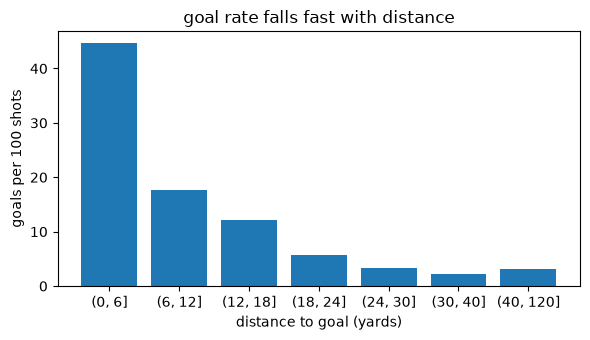

In [9]:
# goals per 100 shots by distance
bins = [0, 6, 12, 18, 24, 30, 40, 120]
distBin = pd.cut(df["distance"], bins)
byDist = df.groupby(distBin, observed=True)["goal"].agg(["mean", "size"])
byDist["mean"] = (byDist["mean"] * 100).round(1)
print(byDist)

plt.figure(figsize=(6, 3.5))
plt.bar(byDist.index.astype(str), byDist["mean"])
plt.xlabel("distance to goal (yards)")
plt.ylabel("goals per 100 shots")
plt.title("goal rate falls fast with distance")
plt.tight_layout()
plt.savefig("../outputs/eda_goal_rate_distance.png", dpi=200)
plt.show()

In [10]:
print(df.groupby("defendersInCone")["goal"].agg(["mean", "size"]).head(6))

flagCols = ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal",
            "shot_aerial_won", "shot_follows_dribble", "shot_redirect"]
for f in flagCols:
    yes = df[df[f] == 1]["goal"].mean() * 100
    no = df[df[f] == 0]["goal"].mean() * 100
    print(f, round(yes, 1), "vs", round(no, 1), "goals per 100,", int(df[f].sum()), "shots have it")

for c in df.columns:
    if c.startswith("shot_body_part_"):
        print(c.replace("shot_body_part_", ""), round(df[df[c] == 1]["goal"].mean() * 100, 1), "goals per 100")

                     mean   size
defendersInCone                 
0                0.146711  47304
1                0.066989  33886
2                0.054319  11506
3                0.056450   4535
4                0.049300   1785
5                0.065177    537
under_pressure 9.5 vs 10.5 goals per 100, 24969 shots have it
shot_first_time 13.6 vs 8.7 goals per 100, 31244 shots have it
shot_one_on_one 25.6 vs 9.5 goals per 100, 4931 shots have it
shot_open_goal 73.7 vs 9.6 goals per 100, 1052 shots have it
shot_aerial_won 7.9 vs 10.5 goals per 100, 8499 shots have it
shot_follows_dribble 14.1 vs 10.3 goals per 100, 64 shots have it
shot_redirect 32.3 vs 10.2 goals per 100, 198 shots have it
Head 11.2 goals per 100
Left Foot 10.1 goals per 100
Other 29.7 goals per 100
Right Foot 10.0 goals per 100


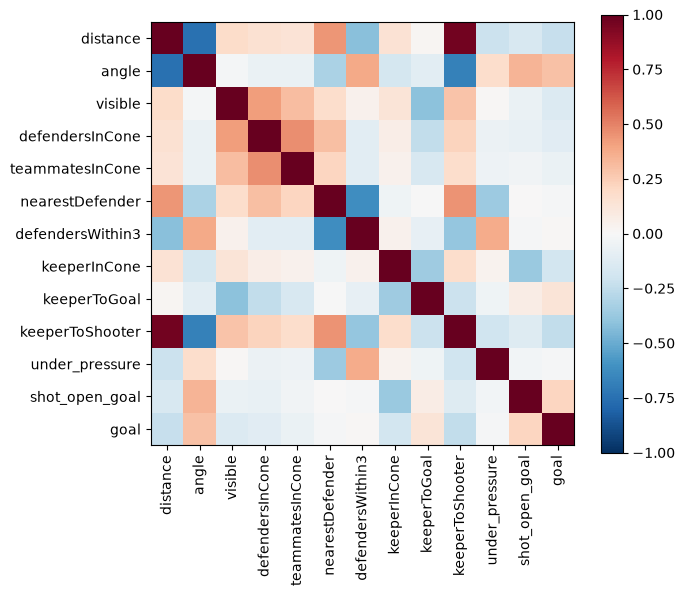

keeperToShooter    -0.244
distance           -0.233
keeperInCone       -0.187
visible            -0.135
defendersInCone    -0.111
teammatesInCone    -0.063
under_pressure     -0.014
nearestDefender    -0.013
defendersWithin3    0.012
keeperToGoal        0.130
shot_open_goal      0.216
angle               0.291
Name: goal, dtype: float64

In [11]:
look = ["distance", "angle", "visible", "defendersInCone", "teammatesInCone", "nearestDefender",
        "defendersWithin3", "keeperInCone", "keeperToGoal", "keeperToShooter",
        "under_pressure", "shot_open_goal", "goal"]
corr = df[look].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(look)), look, rotation=90)
plt.yticks(range(len(look)), look)
plt.colorbar()
plt.tight_layout()
plt.savefig("../outputs/eda_correlations.png", dpi=200)
plt.show()

corr["goal"].drop("goal").sort_values().round(3)

In [12]:
# who is in train and who is in test
matches = loadMatches()
g = df[["match_id", "test"]].merge(matches[["match_id", "gender"]], on="match_id")
pd.crosstab(g["test"], g["gender"], normalize="index").round(3)

gender,female,male
test,,
False,0.179,0.821
True,0.828,0.172


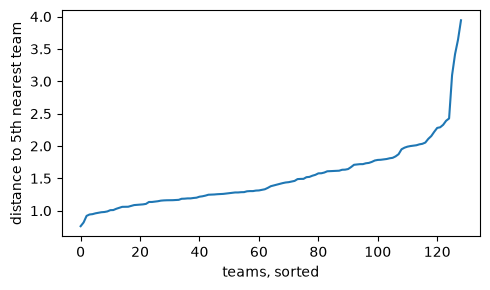

90th percentile: 2.04


In [13]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# team styles from notebook 10, scaled the same way
styles = pd.read_csv("../outputs/team_styles.csv")
nums = ["passesPerMatch", "forwardShare", "averageLength", "longShare",
        "highShare", "finalThirdShare", "crossShare", "risk"]
X = styles[nums].values
X = (X - X.mean(axis=0)) / X.std(axis=0)

# distance to the 5th nearest team, sorted. where the curve bends is a sensible eps
d, _ = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)
k = np.sort(d[:, 4])
plt.figure(figsize=(5, 3))
plt.plot(k)
plt.xlabel("teams, sorted")
plt.ylabel("distance to 5th nearest team")
plt.tight_layout()
plt.show()
print("90th percentile:", round(np.percentile(k, 90), 2))

In [14]:
for eps in [1.5, 1.8, 2.0, 2.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    groups = set(lab)
    groups.discard(-1)
    print("eps", eps, ":", len(groups), "dense groups,", (lab == -1).sum(), "outlier teams")

eps 1.5 : 1 dense groups, 29 outlier teams
eps 1.8 : 1 dense groups, 10 outlier teams
eps 2.0 : 1 dense groups, 4 outlier teams
eps 2.5 : 1 dense groups, 4 outlier teams


In [15]:
lab = DBSCAN(eps=2.0, min_samples=5).fit_predict(X)
styles[lab == -1][["league", "team", "passesPerMatch", "longShare", "risk", "group"]]

,league,team,passesPerMatch,longShare,risk,group
95,International - FIFA World Cup 2022,Spain,871.75,0.119874,0.095672,1
112,International - Women's World Cup 2023,Jamaica Women's,272.25,0.204775,0.308643,0
114,International - Women's World Cup 2023,Morocco Women's,256.25,0.228293,0.315047,0
121,International - Women's World Cup 2023,South Africa Women's,261.50,0.287763,0.310707,0


In [16]:
# counted while cleaning the passes in notebook 02
pd.read_csv("../outputs/pass_findings.csv", index_col=0)

,value
Matches marked 360 available,426.000
Matches skipped (corrupt 360 file),1.000
Matches loaded,425.000
Loaded matches with no framed passes,7.000
Matches in the clean file,418.000
Raw passes,447122.000
Passes left after dropna(),0.000
Blank outcome (completed),367768.000
Incomplete,68464.000
Out,7223.000
